# Libraries

In [1]:
# PACKAGES
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy as sp
from scipy import special, optimize, integrate, interpolate
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
import copy
import time
import random
import pandas as pd
import math
import uuid
from scipy.interpolate import interp1d
%matplotlib inline
from datetime import datetime

# Some warnings show up during the resolution of ODEs, but aren't important to the analysis.
import warnings
warnings.filterwarnings('ignore')

# The magnetic fields are in a separate file.
from mag_field import Bz, Btheta, dBz, dBtheta

# Preliminaries for the evaluation of the dispersion function

In [18]:
# PARAMETERS (normalized; don't change)
y0 = [1, 0] # Initial condition for Euler-Lagrange
R = 1
R0, Rf = 1e-3*R, (1-1e-3)*R

# AUXILIARY FUNCTIONS:

def F(r, m, k, q, zeta):
    return k*Bz(r, q, zeta) + m*Btheta(r, q, zeta)/r

def f(r, m, k, l, q, zeta):
    return r**3*(F(r, m, k, q, zeta)**2 + l)/(m**2 + (k**2)*(r**2))

def df(r, m, k, l, q, zeta):
    dF = k*dBz(r, q, zeta) + m*(dBtheta(r, q, zeta)/r - Btheta(r, q, zeta)/r**2)
    a = r**2*(F(r, m, k, q, zeta)**2 + l)*(3*m**2 + k**2*r**2)/((m**2 + k**2*r**2)**2)
    b = 2*F(r, m, k, q, zeta)*dF*r**3/(m**2 + k**2*r**2)
    return a + b

def g(r, m, k, l, q, zeta):
    den = m**2 + k**2*r**2
    a = (1-(m**2-k**2*r**2)/den**2)*r*(F(r, m, k, q, zeta)**2 + l)
    b1 = 4*m*F(r, m, k, q, zeta)*Btheta(r, q, zeta)/den
    b2 = 2*Btheta(r, q, zeta)*dBtheta(r, q, zeta) + 2*Bz(r, q, zeta)*dBz(r, q, zeta)
    b3 = 2*Btheta(r, q, zeta)**2/r*(2*F(r, m, k, q, zeta)**2/(F(r, m, k, q, zeta)**2 + l) - 1)
    b = k**2*r**2/den*(b1 + b2 + b3)
    return a - b

def F_euler(r, y, m, k, l, q, zeta):
    aux = (g(r, m, k, l, q, zeta)*y[0] - df(r, m, k, l, q, zeta)*y[1])/f(r, m, k, l, q, zeta)
    return np.array([y[1], aux])

def bound_cond_D(m, k, l, xiR, dxiR, q, zeta):
    mod2 = Bz(R, q, zeta)**2 + Btheta(R, q, zeta)**2
    aux = ((m**2 + k**2*R**2)*special.kn(m, abs(k)*R))/(abs(k)*R*special.kn(m-1, abs(k)*R) + m*special.kn(m, abs(k)*R))
    return xiR*(k**2*mod2 + l*(1+aux)) + dxiR*R*(F(R, m, k, q, zeta)**2 + l)

# Evaluation of the dispersion function

In [3]:
# Evaluation of the dispersion function.
# If printsol = True, we plot the solution xi_r.
def disp_F(l, m, k, q, zeta, printsol = False):
    aux_euler2 = lambda y, r : F_euler(r, y, m, k, l, q, zeta)
    rr = np.linspace(R0, Rf, n_ite+1)
    sol2 = integrate.odeint(aux_euler2, y0, rr)
    xiR2, dxiR2 = sol2[-1][0], sol2[-1][1]
    if printsol:
        axes = [r'$r$', r'$\xi_r$']
        title = 'Most unstable perturbation'
        perturbation = [elem[0] for elem in sol2]
        lineplot(rr, perturbation/abs(xiR2), axes, title, markzero = True)
        print('xi(0)= ', sol2[0][0], ', xi\'(0)= ', sol2[0][1])
        print('xi(R)= ', xiR2, ', xi\'(R)= ', R*dxiR2)
    return bound_cond_D(m, k, l, xiR2, dxiR2, q, zeta)

def lininterp(x0, y0, x1, y1, x2):
    m = (y1-y0)/(x1-x0)
    y2 = y1 + m*(x2-x1)
    return y2

# Finds the biggest root of a function in a given interval.
def biggest_root(func_Dlk, l_range):
    D_lk = []
    for l in l_range:
        D_lk.append(func_Dlk(l))
    all_same_sign = all(x > 0 for x in D_lk) or all(x < 0 for x in D_lk)
    if not all_same_sign:
        i = len(D_lk) - 1
        # We are only interested in finding the biggest zero.
        while np.sign(D_lk[i])*np.sign(D_lk[i-1]) > 0:
            i = i - 1
        # Linear interpolation to find the zero. We could do a dicotomic search, but it would be slower.
        return lininterp(D_lk[i-1], l_range[i-1], D_lk[i], l_range[i], 0)
    else:
        return 0

# Finds the dispersion relation between k and lambda, given the magnetic field configuration.
def dispersion_relation(zeta, q, m, k_vals, n_k, l_vals, n_l):
    ks = np.linspace(k_vals[0], k_vals[1], n_k)
    l_range = 10**(np.linspace(l_vals[0], l_vals[1], n_l)) # logarithmically spaced.
    ls = []
    for k in ks:
        D = []
        func_D = lambda l : disp_F(l, m, k, q, zeta) # Definition of a single variable function D(l).
        l = biggest_root(func_D, l_range)
        ls.append(l)
    return ks, ls

# Finding the max growth rate for each magnetic field configuration

In [4]:
# Slightly different from original notebook, as this one also returns the curve (k_range, lambdas)
def lambdamax(zeta, q, m, k_vals, n_k, l_vals, n_l):
    k_range = np.linspace(k_vals[0], k_vals[1], n_k)
    l_range = 10**(np.linspace(l_vals[0], l_vals[1], n_l))
    lmax = 0
    kmax = 0
    lambdas = []
    for k in k_range:
        func_Dlk = lambda l, k=k: disp_F(l, m, k, q, zeta)
        l = biggest_root(func_Dlk, l_range)
        lambdas.append(l)
        if l > lmax:
            lmax = l
            kmax = k
    return lmax, kmax, k_range, lambdas

# ICME data

In [5]:
# Physical constants
mp    = 1.673e-27 # proton mass in Kg
ratio = 1.16 # proton density to mass density ratio (num of helium ions is 4% but have 4x the mass of a proton)
mu0   = 4 * math.pi * 1e-7 # Permeability
SEC   = 86400 # Num of seconds in a day
AU    = 1.496e11 # AU in metres

# Gold-Hoyle profile
OBS_zeta = 1.0

In [6]:
# Density lookup table (median density, from in-situ data)
density_table = pd.DataFrame([
    ("2018-10-30 20:25", "PSP",  178.313),
    ("2018-11-11 23:51", "PSP",  168.320),
    ("2019-03-15 12:11", "PSP",   27.649),
    ("2019-03-24 03:45", "PSP",   50.665),
    ("2020-02-11 05:08", "PSP",   74.548),
    ("2020-06-23 07:07", "PSP",   29.694),
    ("2020-09-12 13:33", "PSP",   24.827),
    ("2021-02-11 16:17", "PSP",   19.910),
    ("2021-05-06 18:26", "SolO",   7.450),
    ("2021-05-27 20:14", "SolO",  16.756),
    ("2021-08-25 01:06", "SolO",  24.286),
    ("2021-10-04 07:01", "SolO",  14.776),
    ("2021-10-15 09:54", "SolO",  24.002),
    ("2021-11-04 01:25", "SolO",   6.783),
    ("2022-01-25 14:02", "SolO",   4.080),
], columns=["start_utc", "spacecraft", "np_p50"])

density_table["start_utc"] = pd.to_datetime(density_table["start_utc"])
 
# Return (np_p50, n_days_diff) for the closest density obs of same spacecraft.
def match_density(t_start_str, sc):
    fmt = "%Y-%m-%d %H:%M"
    t = pd.Timestamp(datetime.strptime(t_start_str, fmt))
    subset = density_table[density_table["spacecraft"] == sc].copy()
    subset["diff"] = (subset["start_utc"] - t).abs()
    best = subset.loc[subset["diff"].idxmin()]
    n_days = best["diff"].total_seconds() / 86400
    return float(best["np_p50"]), round(n_days, 2)

In [7]:
# Obtain T in days from growth rate lambda
def T_days(lam, obs_B0, obs_R, obs_np):
    sigma   = np.sqrt(lam)
    T       = 1.0 / sigma
    obs_rho = ratio * mp * obs_np * 1e6
    factor  = (obs_R / obs_B0) * np.sqrt(mu0 * obs_rho)
    return T * factor / SEC

In [8]:
# ICME table (fitted events only). Source: Good et al. 2023.
# Radius from the mean radial speed, duration and impact parameter: R = <V_R> dt / [2 sqrt(1 - p^2)]
# Columns: event, t_start, t_end, spacecraft, r_au, B0_nT, q, R_au
raw_data = [
    ( 1, "2018-10-30 20:25", "2018-10-31 08:19", "PSP",  0.26,  56.0, -5.2, 0.04766),
    ( 2, "2018-11-11 23:51", "2018-11-12 05:59", "PSP",  0.25, 100.6,  7.3, 0.02917),
    ( 3, "2019-03-15 12:11", "2019-03-15 17:49", "PSP",  0.55,  36.0,  3.6, 0.03158),
    ( 4, "2019-03-24 03:45", "2019-03-24 17:38", "PSP",  0.39,  36.7,  3.0, 0.06789),
    ( 5, "2020-02-11 05:08", "2020-02-11 11:35", "PSP",  0.42,  43.6,  4.6, 0.02615),
    ( 7, "2020-06-23 07:07", "2020-06-23 16:52", "PSP",  0.48,  20.1, -2.7, 0.05962),
    ( 9, "2020-09-12 13:33", "2020-09-12 19:35", "PSP",  0.47,  23.7,  7.3, 0.03193),
    (11, "2021-02-11 16:17", "2021-02-12 00:57", "PSP",  0.63,  15.4,  2.6, 0.03956),
    (13, "2021-05-06 18:26", "2021-05-07 15:07", "SolO", 0.91,  13.6, -3.1, 0.10885),
    (15, "2021-05-27 20:14", "2021-05-28 10:27", "SolO", 0.95,  11.1,  4.0, 0.05412),
    (23, "2021-08-25 01:06", "2021-08-25 10:43", "SolO", 0.63,  16.2, -2.3, 0.04335),
    (24, "2021-10-04 07:01", "2021-10-04 12:59", "SolO", 0.65,  11.6, -6.6, 0.01948),
    (26, "2021-10-15 09:54", "2021-10-15 23:11", "SolO", 0.72,  14.7, -2.2, 0.05293),
    (27, "2021-11-04 01:25", "2021-11-04 19:47", "SolO", 0.83,  20.6, -1.0, 0.14967),
    (28, "2022-01-25 14:02", "2022-01-27 07:15", "SolO", 0.89,  12.5, -0.7, 0.20915),
]
n_events = len(raw_data)
 
# Return duration as 'Xh Ym' from start to end of the event.
def fmt_duration(t_start_str, t_end_str):
    fmt = "%Y-%m-%d %H:%M"
    delta = datetime.strptime(t_end_str, fmt) - datetime.strptime(t_start_str, fmt)
    total_minutes = int(delta.total_seconds() // 60)
    d =  total_minutes // (60 * 24)
    h =  total_minutes // 60
    m =  total_minutes % 60
    parts = []
    if h: parts.append(f"{h}h")
    if m: parts.append(f"{m}m")
    return " ".join(parts) if parts else "0m"

# Growth rate analysis for the events above

When running the cell below, after the analysis of each event, the lambda plot is shown.
Worth checking lambdamax is not clipping at k-range edges.
RED dot = kmax found. If it sits at the left or right edge, the k_vals range is too narrow.
If the curve drops to 0 in the middle, means the range for lambda (l_vals) needs widening on the upper bound.

In [9]:
# Types of instability to be analyzed:
ms = [1, 2]

# Numerical PDE solution params:
n_ite  = 30
n_k    = 80
n_l    = 30

In [10]:
# Run growth rate analysis for a subset of events

def run_analysis(raw_data_subset):
    records_out = []

    for (ev, t_start, t_end, sc, r_au, B0_nT, q, R_rope_au) in raw_data_subset:
        i_global = next(j+1 for j, rd in enumerate(raw_data) if rd[0] == ev)
        pct = 100 * i_global / n_events
        print(f"\n[{i_global}/{n_events}  {pct:.0f}%]  Event {ev}  |  {sc}  |  "
              f"r={r_au} au  B0={B0_nT} nT  q={q}")

        obs_B0 = B0_nT * 1e-9
        obs_np, n_days_rho = match_density(t_start, sc)
        print(f"  density match: np={obs_np:.2f} cm^-3  (NdaysRho={n_days_rho:.2f})")

        q_abs     = np.abs(q)
        R_rope_m  = R_rope_au * AU
        q_norm    = 2 * np.pi * q_abs * R_rope_au
        print(f"  R_rope = {R_rope_au:.4f} au,  q_norm = {q_norm:.3f}")
        print(f"  [params: n_ite={n_ite}, l_vals={l_vals}, n_k={n_k}, n_l={n_l}]")

        row = {
            "Event":       ev,
            "Start (UT)":  t_start,
            "Duration":    fmt_duration(t_start, t_end),
            "Mission":     sc,
            "B0 (nT)":     B0_nT,
            "r (au)":      r_au,
            "R_rope (au)": round(R_rope_au, 4),
            "q (au^-1)":   q,
            "np":          round(obs_np, 2),
            "NdaysRho":    n_days_rho,
        }

        fig, axes = plt.subplots(1, len(ms), figsize=(5 * len(ms), 3.5))
        if len(ms) == 1:
            axes = [axes]
        fig.suptitle(f"Event {ev}  |  {sc}  |  q={q}  B0={B0_nT} nT  r={r_au} au",
                     fontsize=10)

        for ax, m in zip(axes, ms):
            k_vals_m = get_k_vals(m, q_norm)
            lam, kmax, k_range, lambdas = lambdamax(OBS_zeta, q_norm, m, k_vals_m, n_k, l_vals, n_l)

            span    = k_range[-1] - k_range[0]
            clipped = (lam > 0) and (
                abs(kmax - k_range[0])  < 0.05 * abs(span) or
                abs(kmax - k_range[-1]) < 0.05 * abs(span)
            )

            ax.plot(k_range, lambdas, color="steelblue", lw=1.5)
            ax.axhline(0, color="gray", lw=0.8, ls="--")
            ax.scatter([kmax], [lam], color="red", zorder=5, label=f"kmax={kmax:.3f}")
            ax.set_xlabel("k")
            ax.set_ylabel("lambda")
            ax.legend(fontsize=8)

            if clipped:
                ax.set_facecolor("#fff0f0")
                ax.set_title(f"m={m}  *** EDGE CLIP ***", color="red", fontsize=9)
            else:
                ax.set_title(f"m={m}  lmax={lam:.3e}", fontsize=9)

            # Refine around the maximum: finer k grid (one step either side) and narrow lambda range
            if lam > 0:
                dk = k_range[1] - k_range[0]
                l_fine = [np.log10(lam) - 0.6, np.log10(lam) + 0.4]
                lam, kmax, _, _ = lambdamax(OBS_zeta, q_norm, m, [kmax - dk, kmax + dk], 11, l_fine, 30)
                if lam == 0:
                    print(f"  WARNING: refinement found no root for m={m}, check this event")                
            if lam > 0:
                T_d   = T_days(lam, obs_B0, R_rope_m, obs_np)
                sigma = 1.0 / T_d
                print(f"  m={m}  ->  sigma={sigma:.3e} d^-1  T={T_d:.1f} days  (k/q={kmax/q_norm:.5f})")
            else:
                sigma = np.nan
                T_d   = np.nan
                print(f"  m={m}  ->  no unstable mode found")

            row[f"sigma_m{m}"] = sigma if not np.isnan(sigma) else np.nan
            row[f"T_m{m}_d"]   = round(T_d,   2) if not np.isnan(T_d)   else np.nan

        plt.tight_layout()
        plt.show()
        records_out.append(row)

    return records_out

In [11]:
# Displaying twist for each measured event.
for ev, *_, q, R_au in raw_data:
    print(ev, round(2 * np.pi * abs(q) * R_au, 3))

1 1.557
2 1.338
3 0.714
4 1.28
5 0.756
7 1.011
9 1.465
11 0.646
13 2.12
15 1.36
23 0.626
24 0.808
26 0.732
27 0.94
28 0.92



[1/15  7%]  Event 1  |  PSP  |  r=0.26 au  B0=56.0 nT  q=-5.2
  density match: np=178.31 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0477 au,  q_norm = 1.557
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=7.464e-02 d^-1  T=13.4 days  (k/q=-0.70222)
  m=2  ->  sigma=3.038e-02 d^-1  T=32.9 days  (k/q=-1.77716)


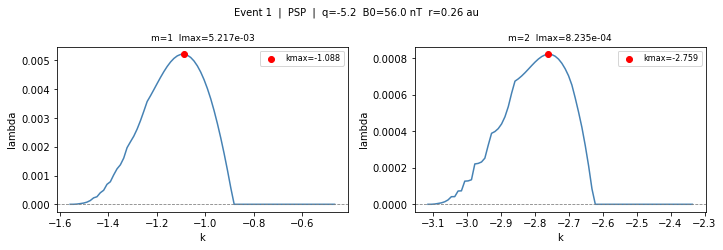


[2/15  13%]  Event 2  |  PSP  |  r=0.25 au  B0=100.6 nT  q=7.3
  density match: np=168.32 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0292 au,  q_norm = 1.338
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=1.622e-01 d^-1  T=6.2 days  (k/q=-0.75361)
  m=2  ->  sigma=7.385e-02 d^-1  T=13.5 days  (k/q=-1.79867)


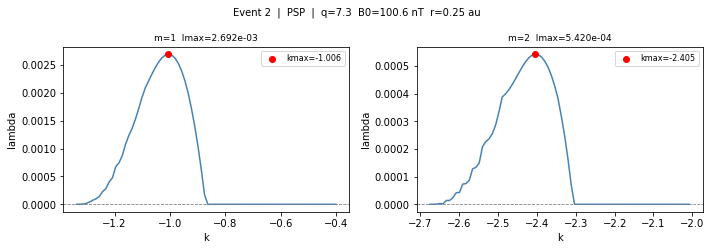


[3/15  20%]  Event 3  |  PSP  |  r=0.55 au  B0=36.0 nT  q=3.6
  density match: np=27.65 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0316 au,  q_norm = 0.714
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=2.145e-02 d^-1  T=46.6 days  (k/q=-0.90776)
  m=2  ->  sigma=1.416e-02 d^-1  T=70.6 days  (k/q=-1.90751)


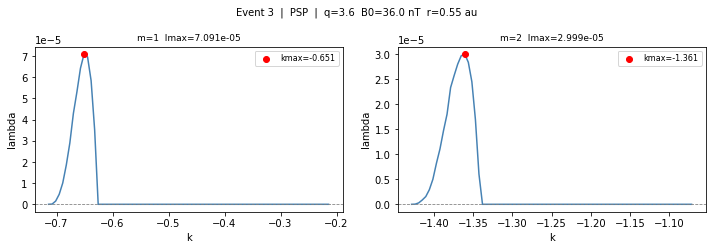


[4/15  27%]  Event 4  |  PSP  |  r=0.39 au  B0=36.7 nT  q=3.0
  density match: np=50.66 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0679 au,  q_norm = 1.280
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=4.170e-02 d^-1  T=24.0 days  (k/q=-0.76778)
  m=2  ->  sigma=1.961e-02 d^-1  T=51.0 days  (k/q=-1.80627)


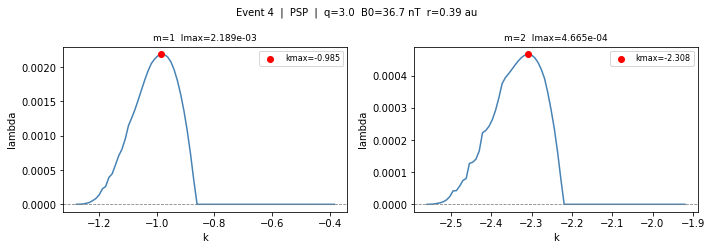


[5/15  33%]  Event 5  |  PSP  |  r=0.42 au  B0=43.6 nT  q=4.6
  density match: np=74.55 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0261 au,  q_norm = 0.756
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=2.305e-02 d^-1  T=43.4 days  (k/q=-0.89890)
  m=2  ->  sigma=1.486e-02 d^-1  T=67.3 days  (k/q=-1.89992)


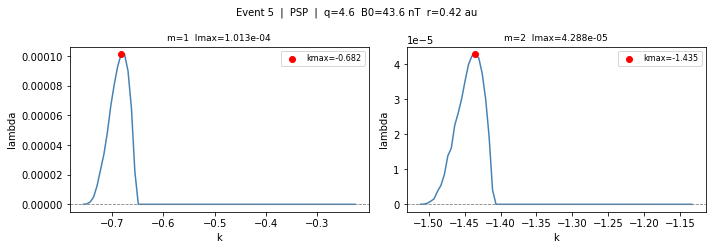


[6/15  40%]  Event 7  |  PSP  |  r=0.48 au  B0=20.1 nT  q=-2.7
  density match: np=29.69 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0596 au,  q_norm = 1.011
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=1.819e-02 d^-1  T=55.0 days  (k/q=-0.83511)
  m=2  ->  sigma=1.004e-02 d^-1  T=99.6 days  (k/q=-1.84930)


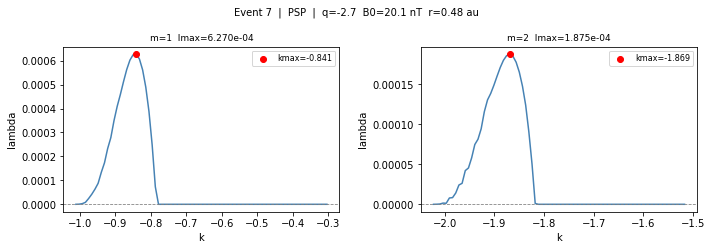


[7/15  47%]  Event 9  |  PSP  |  r=0.47 au  B0=23.7 nT  q=7.3
  density match: np=24.83 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0319 au,  q_norm = 1.465
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=1.113e-01 d^-1  T=9.0 days  (k/q=-0.72348)
  m=2  ->  sigma=4.737e-02 d^-1  T=21.1 days  (k/q=-1.78475)


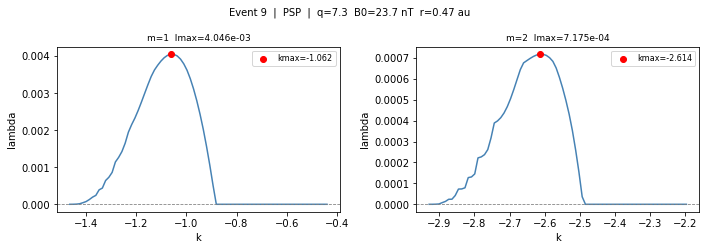


[8/15  53%]  Event 11  |  PSP  |  r=0.63 au  B0=15.4 nT  q=2.6
  density match: np=19.91 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0396 au,  q_norm = 0.646
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=6.136e-03 d^-1  T=163.0 days  (k/q=-0.92371)
  m=2  ->  sigma=4.205e-03 d^-1  T=237.8 days  (k/q=-1.92143)


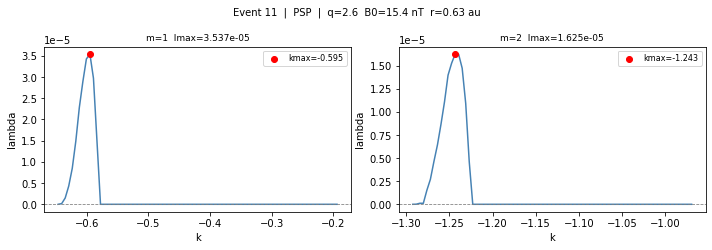


[9/15  60%]  Event 13  |  SolO  |  r=0.91 au  B0=13.6 nT  q=-3.1
  density match: np=7.45 cm^-3  (NdaysRho=0.00)
  R_rope = 0.1089 au,  q_norm = 2.120
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=6.536e-02 d^-1  T=15.3 days  (k/q=-0.61008)
  m=2  ->  sigma=2.218e-02 d^-1  T=45.1 days  (k/q=-1.75311)


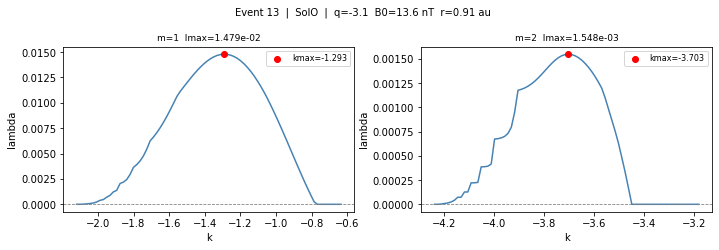


[10/15  67%]  Event 15  |  SolO  |  r=0.95 au  B0=11.1 nT  q=4.0
  density match: np=16.76 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0541 au,  q_norm = 1.360
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=3.177e-02 d^-1  T=31.5 days  (k/q=-0.74829)
  m=2  ->  sigma=1.428e-02 d^-1  T=70.0 days  (k/q=-1.79614)


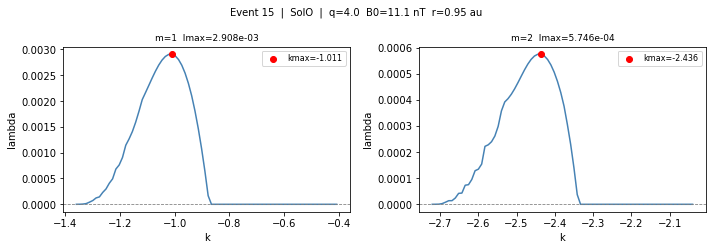


[11/15  73%]  Event 23  |  SolO  |  r=0.63 au  B0=16.2 nT  q=-2.3
  density match: np=24.29 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0433 au,  q_norm = 0.626
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=4.787e-03 d^-1  T=208.9 days  (k/q=-0.92725)
  m=2  ->  sigma=3.314e-03 d^-1  T=301.7 days  (k/q=-1.92523)


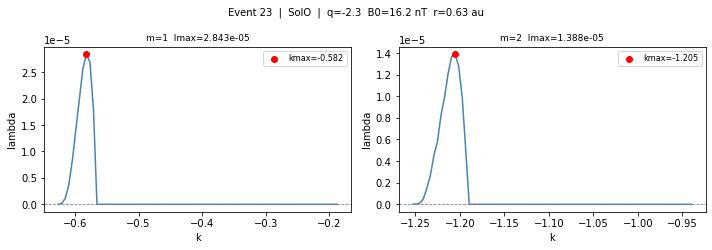


[12/15  80%]  Event 24  |  SolO  |  r=0.65 au  B0=11.6 nT  q=-6.6
  density match: np=14.78 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0195 au,  q_norm = 0.808
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=2.296e-02 d^-1  T=43.6 days  (k/q=-0.88650)
  m=2  ->  sigma=1.435e-02 d^-1  T=69.7 days  (k/q=-1.88980)


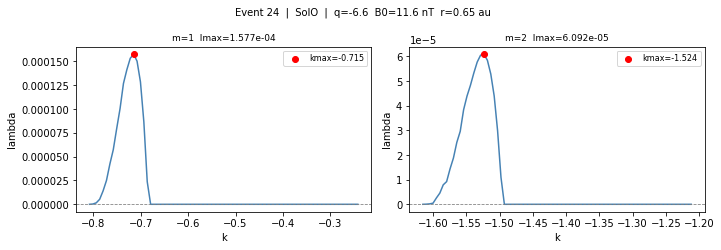


[13/15  87%]  Event 26  |  SolO  |  r=0.72 au  B0=14.7 nT  q=-2.2
  density match: np=24.00 cm^-3  (NdaysRho=0.00)
  R_rope = 0.0529 au,  q_norm = 0.732
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=6.078e-03 d^-1  T=164.5 days  (k/q=-0.90422)
  m=2  ->  sigma=3.972e-03 d^-1  T=251.8 days  (k/q=-1.90498)


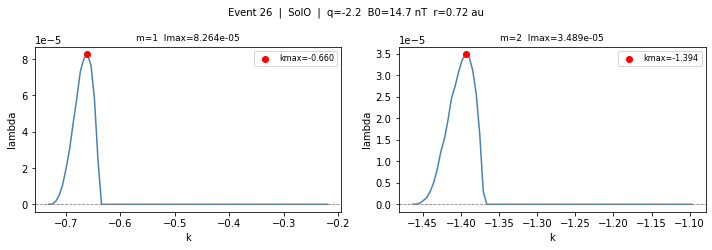


[14/15  93%]  Event 27  |  SolO  |  r=0.83 au  B0=20.6 nT  q=-1.0
  density match: np=6.78 cm^-3  (NdaysRho=0.00)
  R_rope = 0.1497 au,  q_norm = 0.940
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=1.255e-02 d^-1  T=79.7 days  (k/q=-0.85283)
  m=2  ->  sigma=7.240e-03 d^-1  T=138.1 days  (k/q=-1.86322)


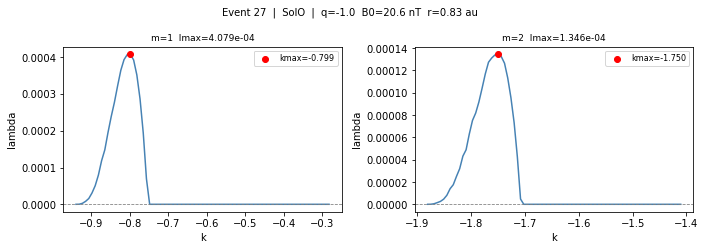


[15/15  100%]  Event 28  |  SolO  |  r=0.89 au  B0=12.5 nT  q=-0.7
  density match: np=4.08 cm^-3  (NdaysRho=0.00)
  R_rope = 0.2092 au,  q_norm = 0.920
  [params: n_ite=30, l_vals=[-8, -1], n_k=80, n_l=30]
  m=1  ->  sigma=6.576e-03 d^-1  T=152.1 days  (k/q=-0.85815)
  m=2  ->  sigma=3.842e-03 d^-1  T=260.3 days  (k/q=-1.86702)


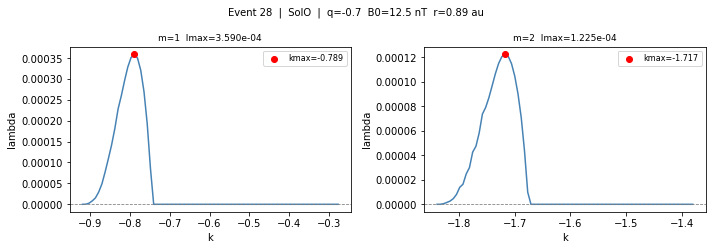

In [12]:
# All events (q = 0.6-2.1: the unstable band starts just above k = -mq and the peak moves away from it as q grows)
l_vals = [-8, -1]
def get_k_vals(m, q):
    # start just above k = -mq: there F = 0 for zeta = 1 and the solver has a numerical problem
    if m == 1:
        return [-0.9999 * q, -0.3 * q]
    elif m == 2:
        return [-1.9999 * q, -1.5 * q]
    else:
        raise ValueError(f"m={m} not supported. Validate k_vals ranges before extending to higher modes.")
records = run_analysis(raw_data)

# Save
results = pd.DataFrame(records)
results.to_csv("icme_instability_results.csv", index=False, header=False)
nonzero = results[results["NdaysRho"] > 0][["Event", "Start (UT)", "Mission", "NdaysRho"]]

# Write LaTeX table

In [19]:
def fmt_cell(val, decimals=None):
    if pd.isna(val):
        return "$\\cdots$"
    if decimals is not None:
        return f"{float(val):.{decimals}f}"
    return str(val)

def fmt_days(T_days):
    if pd.isna(T_days):
        return "$\\cdots$"
    return f"{T_days:.1f}" if T_days < 10 else f"{T_days:.0f}"

def fmt_signed(val):
    return f"${val:.1f}$" if val < 0 else f"{val:.1f}"

# Density match check
nonzero = results[results["NdaysRho"] > 0][["Event", "Start (UT)", "Mission", "NdaysRho"]]
if nonzero.empty:
    print("Density match check: all events matched to same-day observation.")
else:
    print("WARNING: the following events have a density observation offset:")
    print(nonzero.to_string(index=False))

# LaTeX rows (events renumbered 1-15 as in the paper, T in days)
tex_rows = []
for i, (_, r) in enumerate(results.iterrows(), start=1):
    q_norm = 2 * np.pi * abs(r["q (au^-1)"]) * r["R_rope (au)"]
    cols = [
        str(i),
        r["Start (UT)"],
        r["Duration"],
        "SO" if r["Mission"] == "SolO" else r["Mission"],
        f"{r['r (au)']:.2f}",
        f"{r['np']:.1f}",
        f"{r['B0 (nT)']:.1f}",
        fmt_signed(r["q (au^-1)"]),
        f"{r['R_rope (au)']:.3f}",
        f"{q_norm:.2f}",
        fmt_days(r["T_m1_d"]),
        fmt_days(r["T_m2_d"]),
    ]
    tex_rows.append("    " + " & ".join(cols) + " \\\\")

rows_str = "\n".join(tex_rows)

lines = [
    r"\begin{table*}[ht]",
    r"  \footnotesize",
    r"  \caption{%",
    r"    Observed parameters and instability timescales for 15 ICMEs detected by PSP and Solar Orbiter (SO).",
    r"    $r$ (au) is the heliocentric distance and $n_p$ (cm$^{-3}$) the median proton density during the flux rope crossing.",
    r"    $B_0$ (nT) and $\Gamma$ (turns au$^{-1}$) are the axial field strength and the twist per unit length from the Gold--Hoyle fits of \cite{goodTurbulence2023}.",
    r"    $R$ (au) is the flux rope radius, estimated from the mean radial speed, the crossing duration and the impact parameter, and $q = 2\pi|\Gamma| R$ is the dimensionless twist parameter of the modified Gold--Hoyle model.",
    r"    $T$ (days) is the growth timescale of the azimuthal modes $m = 1$ and $m = 2$ for $\fpar = 1$.",
    r"    Events have been renumbered 1--15 and no longer correspond to event IDs in \cite{goodTurbulence2023}.%",
    r"  }",
    r"  \label{tab:icme}",
    r"  \setlength{\tabcolsep}{2.5pt}",
    r"  \centering",
    r"  \begin{tabular}{c l c c r r r r r r r r}",
    r"    \toprule",
    r"    \multicolumn{6}{c}{MFR observation} &",
    r"    \multicolumn{4}{c}{Flux rope} &",
    r"    \multicolumn{2}{c}{$T$ (days)} \\",
    r"    \cmidrule(lr){1-6}\cmidrule(lr){7-10}\cmidrule(lr){11-12}",
    r"    {No.} & {Start (UT)} & {Dur.} & {S/C} & {$r$} & {$n_p$} &",
    r"    {$B_{0}$} & {$\Gamma$} & {$R$} & {$q$} &",
    r"    {$m=1$} & {$m=2$} \\",
    r"    \midrule",
    rows_str,
    r"    \bottomrule",
    r"  \end{tabular}",
    r"\end{table*}",
]
tex = "\n".join(lines)

with open("icme_tables.tex", "w") as tex_file:
    tex_file.write(tex)
print("LaTeX table saved to icme_tables.tex")

Density match check: all events matched to same-day observation.
LaTeX table saved to icme_tables.tex


# Critical twist per radius

In [20]:
def max_growth_rate(q, l_vals, m=1, zeta=1.0):
    # k/q = -(1 - delta), delta log-spaced: dense near k = -mq, where the band sits at low twist,
    # coarse further away, where the peak sits at high twist (k ~ -0.54 q for the kink)
    k_grid = -(1 - np.logspace(-3, np.log10(0.7), 40)) * m * q
    l_range = 10**np.arange(l_vals[0], l_vals[1], 0.3)
    lams = [biggest_root(lambda l, k=k: disp_F(l, m, k, q, zeta), l_range) for k in k_grid]
    i = int(np.argmax(lams))
    if lams[i] == 0:
        return 0
    # refine between the neighbouring k values, with a narrow lambda range
    k_lo, k_hi = k_grid[max(i - 1, 0)], k_grid[min(i + 1, len(k_grid) - 1)]
    l_fine = [np.log10(lams[i]) - 0.6, np.log10(lams[i]) + 0.4]
    return lambdamax(zeta, q, m, [k_lo, k_hi], 11, l_fine, 30)[0]

# Kink growth rate (m = 1, zeta = 1) versus q, in units of 1/tau_A with tau_A = R sqrt(mu0 rho)/B0.
# The growth rate increases with q, so each lambda search starts just below the previous result.
q_grid = np.logspace(-1, 2, 21)
lam_prev = 1e-12
sigma_hat = []
for q in q_grid:
    lam = max_growth_rate(q, [np.log10(lam_prev) - 0.6, np.log10(lam_prev) + 2.5])
    sigma_hat.append(np.sqrt(lam))
    lam_prev = lam
    print(f'q = {q:.3f}  sigma_hat = {np.sqrt(lam):.4e}')
np.savetxt('sheet_sigma_q.csv', [q_grid, sigma_hat], delimiter=',')

q = 0.100  sigma_hat = 4.5690e-06
q = 0.141  sigma_hat = 1.8054e-05
q = 0.200  sigma_hat = 7.0830e-05
q = 0.282  sigma_hat = 2.7409e-04
q = 0.398  sigma_hat = 1.0314e-03
q = 0.562  sigma_hat = 3.6853e-03
q = 0.794  sigma_hat = 1.2000e-02
q = 1.122  sigma_hat = 3.3536e-02
q = 1.585  sigma_hat = 7.5099e-02
q = 2.239  sigma_hat = 1.3145e-01
q = 3.162  sigma_hat = 1.9537e-01
q = 4.467  sigma_hat = 2.7725e-01
q = 6.310  sigma_hat = 3.9177e-01
q = 8.913  sigma_hat = 5.5343e-01
q = 12.589  sigma_hat = 7.8175e-01
q = 17.783  sigma_hat = 1.1043e+00
q = 25.119  sigma_hat = 1.5598e+00
q = 35.481  sigma_hat = 2.2033e+00
q = 50.119  sigma_hat = 3.1122e+00
q = 70.795  sigma_hat = 4.3959e+00
q = 100.000  sigma_hat = 6.2085e+00


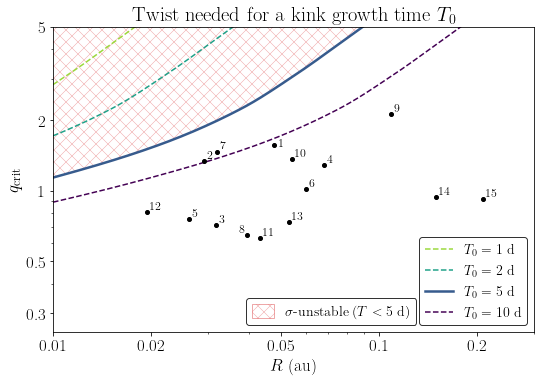

Plot saved to: critical_twist.png


In [21]:
import os
from scipy.interpolate import PchipInterpolator
from matplotlib.ticker import FormatStrFormatter, NullFormatter
from matplotlib.patches import Patch

# Same settings as main_notebook, so text matches the other figures
plt.rcParams['text.usetex'] = True
plt.rc('font', **{'family': 'serif', 'serif': ['Computer Modern Roman']})
plt.rcParams.update({'font.size': 17})
plt.rcParams['hatch.linewidth'] = 0.4

q_grid, sigma_hat = np.loadtxt('sheet_sigma_q.csv', delimiter=',')
q_of_sigma = PchipInterpolator(np.log10(sigma_hat), np.log10(q_grid))   # inverse of sigma_hat(q), log-log

V_A = 100e3                               # Alfven speed (m/s), median of the 15 events
growth_times = [1, 2, 5, 10]              # kink growth time T (days), same T as in Table 1
R_au = np.logspace(-2, np.log10(0.3), 200)   # flux rope radius (au)
tau_A = R_au * AU / V_A / SEC             # Alfven time (days)

# 7.4 in wide: included at 0.67\textwidth, the text prints at the same size as in the other figures
fig, ax = plt.subplots(figsize=(7.4, 5.2), constrained_layout=True)
hatch_color = (0.84, 0.15, 0.16, 0.5)              # tab:red at half opacity, so the T curves stay visible
colors = plt.get_cmap('viridis')(np.linspace(0.85, 0, len(growth_times)))   # short T = light color
for T, c in zip(growth_times, colors):
    q_crit = 10**q_of_sigma(np.log10(tau_A / T))      # twist at which the kink growth time equals T
    ls = '-' if T == 5 else '--'                      # T = 5 d (about the Sun-1 au transit) is the threshold used
    ax.plot(R_au, q_crit, color=c, lw=2.5 if T == 5 else 1.5, ls=ls, label=rf'$T_0 = {T}$ d')
    if T == 5:
        # hatched region above the threshold: the kink grows faster than T = 5 d
        ax.fill_between(R_au, q_crit, 10, facecolor='none', edgecolor=hatch_color, hatch='xx', lw=0, zorder=0)
leg_T = ax.legend(loc='lower right', fontsize=14)
leg_T.get_frame().set_edgecolor('black')
ax.add_artist(leg_T)
unstable = Patch(facecolor='white', edgecolor=hatch_color, hatch='xx', lw=0.8)
ax.legend([unstable], [r'$\sigma$-unstable ($T < 5$ d)'], loc='lower right', bbox_to_anchor=(0.77, 0),
          fontsize=14, handlelength=1.6, handleheight=1.2).get_frame().set_edgecolor('black')

# Events analyzed (R and q as in Table 1), labeled with their event number
R_events = [rd[7] for rd in raw_data]
q_events = [2 * np.pi * abs(rd[6]) * rd[7] for rd in raw_data]
ax.plot(R_events, q_events, 'o', color='k', ms=4)
for i, (R_ev, q_ev) in enumerate(zip(R_events, q_events)):
    dx = -3 if i + 1 == 8 else 3 # event 8 labeled on the left, it sits next to event 11
    dx = 5 if i + 1 == 1 else dx
    dy = -1 if i + 1 == 1 else 3 # event 1 also causes trouble
    ax.annotate(str(i + 1), (R_ev, q_ev), xytext=(dx, dy), textcoords='offset points',
                ha='right' if dx < 0 else 'left', fontsize=12)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(0.01, 0.3)
ax.set_ylim(0.25, 5)
ax.set_xticks([0.01, 0.02, 0.05, 0.1, 0.2])
ax.set_yticks([0.3, 0.5, 1, 2, 5])
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(FormatStrFormatter('%g'))
    axis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r'$R$ (au)')
ax.set_ylabel(r'$q_{\rm crit}$')
ax.set_title(r'Twist needed for a kink growth time $T_0$')

file_path = 'critical_twist.png'
plt.savefig(file_path, dpi=300)
plt.show()
print('Plot saved to:', file_path)